
# dataset [Casting Product Image Data for Quality Inspection](https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product)



## Setup

In [ ]:
import os, json, time, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

import tensorflow as tf
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

print(tf.__version__, tf.config.list_physical_devices("GPU"))

I0000 00:00:1794074887.911980     573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794074888.795444     573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


2.21.0 []


## Load dataset
Upload `archive.zip`  ke folder utama Google Drive atau langsung ke panel Files di Colab.

In [ ]:
import zipfile

ZIP = "archive.zip"
if not os.path.exists(ZIP):
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP = "/content/drive/MyDrive/archive.zip"

with zipfile.ZipFile(ZIP) as z:
    z.extractall("data", members=[m for m in z.namelist() if m.startswith("casting_data/")])

DATA_DIR = "data/casting_data/casting_data"
os.listdir(DATA_DIR)

['test', 'train']

## EDA

In [ ]:
LABELS = {"def_front": 1, "ok_front": 0}

rows = []
for split in ["train", "test"]:
    for cls, y in LABELS.items():
        folder = os.path.join(DATA_DIR, split, cls)
        for f in sorted(os.listdir(folder)):
            rows.append((split, cls, y, os.path.join(folder, f)))
df = pd.DataFrame(rows, columns=["split", "kelas", "label", "path"])

dist = pd.crosstab(df.split, df.kelas, margins=True, margins_name="Total")
dist["% cacat"] = (dist.def_front / dist.Total * 100).round(1)
dist

kelas,def_front,ok_front,Total,% cacat
split,,,,
test,453,262,715,63.4
train,3758,2875,6633,56.7
Total,4211,3137,7348,57.3


In [ ]:
sizes, modes, brightness, gray = [], [], [], []
for p in df.path:
    im = Image.open(p)
    a = np.asarray(im)
    sizes.append(im.size)
    modes.append(im.mode)
    brightness.append(a.mean())
    gray.append(bool((a[..., 0] == a[..., 1]).all() and (a[..., 1] == a[..., 2]).all()))

df["brightness"] = brightness
print("ukuran :", pd.Series(sizes).value_counts().to_dict())
print("mode   :", pd.Series(modes).value_counts().to_dict())
print("RGB dengan 3 kanal identik:", np.mean(gray) * 100, "%")
df.groupby("kelas").brightness.agg(["mean", "std"]).round(1)

ukuran : {(300, 300): 7348}
mode   : {'RGB': 7348}
RGB dengan 3 kanal identik: 100.0 %


,mean,std
kelas,,
def_front,139.3,5.8
ok_front,149.8,6.5


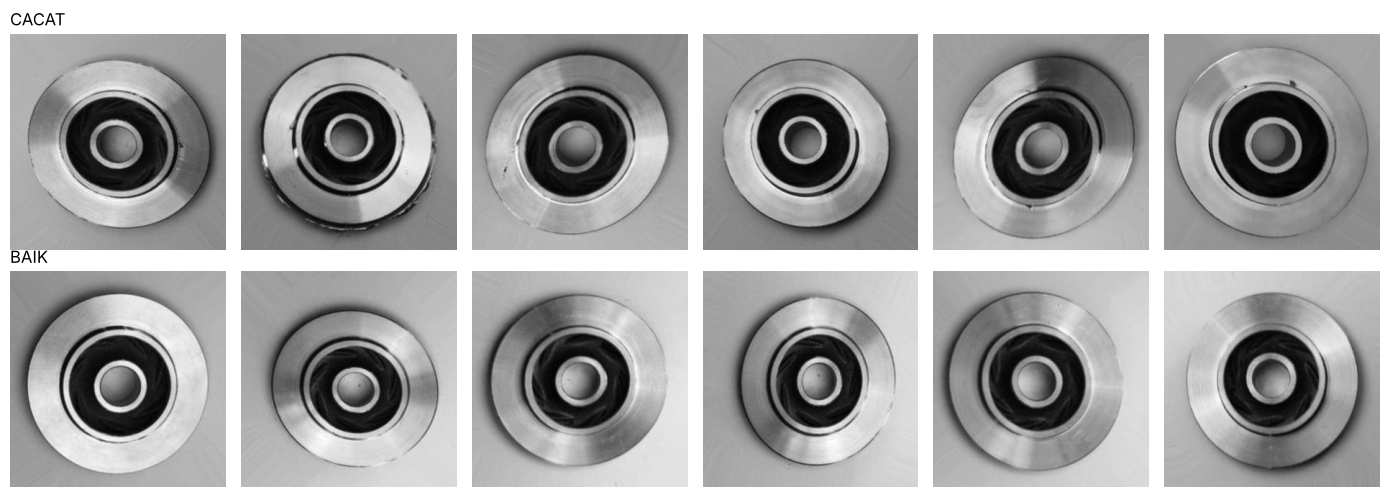

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for r, cls in enumerate(LABELS):
    sample = df[(df.kelas == cls) & (df.split == "train")].sample(6, random_state=SEED)
    for c, p in enumerate(sample.path):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title("CACAT" if cls == "def_front" else "BAIK", loc="left")
plt.tight_layout()
plt.savefig(f"{OUT}/contoh_citra.png", dpi=120)
plt.show()

## Preprocessing
Cek duplikat train–test pakai hash piksel

In [ ]:
df["hash"] = [hashlib.md5(np.asarray(Image.open(p)).tobytes()).hexdigest() for p in df.path]
train_hash = set(df[df.split == "train"].hash)
df["dup"] = (df.split == "test") & df.hash.isin(train_hash)

print("duplikat train-test:", df.dup.sum(), df[df.dup].kelas.value_counts().to_dict())
print("duplikat dalam train:", df[df.split == "train"].hash.duplicated().sum())
print("duplikat dalam test :", df[df.split == "test"].hash.duplicated().sum())

duplikat train-test: 64 {'ok_front': 64}
duplikat dalam train: 0
duplikat dalam test : 0


In [ ]:
def load(paths):
    imgs = [np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) for p in paths]
    return np.stack(imgs)[..., None].astype("uint8")

train_df = df[df.split == "train"]
tr_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df.label, random_state=SEED)
test_all = df[df.split == "test"]
test_df = test_all[~test_all.dup]

X_tr, y_tr = load(tr_df.path), tr_df.label.values
X_val, y_val = load(val_df.path), val_df.label.values
X_te, y_te = load(test_df.path), test_df.label.values
X_te_all, y_te_all = load(test_all.path), test_all.label.values

split_info = pd.DataFrame(
    {"cacat": [y.sum() for y in (y_tr, y_val, y_te, y_te_all)],
     "baik": [(y == 0).sum() for y in (y_tr, y_val, y_te, y_te_all)]},
    index=["train", "validasi", "test bersih", "test asli"])
split_info["total"] = split_info.sum(axis=1)
split_info

,cacat,baik,total
train,3006,2300,5306
validasi,752,575,1327
test bersih,453,198,651
test asli,453,262,715


## Fungsi evaluasi
Ambang τ dipilih di data validasi dengan biaya kesalahan paling kecil: **10 × FN + 1 × FP**.

In [ ]:

C_FN, C_FP = 10, 1

def pick_threshold(y, prob):
    best_t, best_cost = 0.5, None
    for t in np.round(np.arange(0.01, 1.00, 0.01), 2):
        pred = (prob >= t).astype(int)
        fn = ((pred == 0) & (y == 1)).sum()
        fp = ((pred == 1) & (y == 0)).sum()
        cost = C_FN * fn + C_FP * fp
        if best_cost is None or cost < best_cost:
            best_t, best_cost = float(t), cost
    return best_t

def evaluate(y, prob, t):
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "ambang": t,
        "accuracy": accuracy_score(y, pred),
        "recall_cacat": recall_score(y, pred),
        "precision_cacat": precision_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred),
        "fpr": fp / (fp + tn),
        "roc_auc": roc_auc_score(y, prob) if len(set(prob)) > 1 else 0.5,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "biaya_relatif": int(C_FN * fn + C_FP * fp),
    }

results = {"B0 Mayoritas": evaluate(y_te, np.ones(len(y_te)), 0.5)}
pd.DataFrame(results).T

,ambang,accuracy,recall_cacat,precision_cacat,f1,fpr,roc_auc,TP,FP,FN,TN,biaya_relatif
B0 Mayoritas,0.5,0.695853,1.0,0.695853,0.820652,1.0,0.5,453.0,198.0,0.0,0.0,198.0


## Baseline: HOG + Logistic Regression

In [ ]:
from skimage.feature import hog
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def hog_features(X):
    return np.stack([
        hog(np.asarray(Image.fromarray(x[..., 0]).resize((128, 128))),
            orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
        for x in X])

H_tr, H_val, H_te = hog_features(X_tr), hog_features(X_val), hog_features(X_te)

hog_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
hog_lr.fit(H_tr, y_tr)

t_hog = pick_threshold(y_val, hog_lr.predict_proba(H_val)[:, 1])
results["B1 HOG + LogReg"] = evaluate(y_te, hog_lr.predict_proba(H_te)[:, 1], t_hog)
print("fitur HOG:", H_tr.shape[1], "| ambang:", t_hog)
pd.DataFrame(results).T

fitur HOG: 1764 | ambang: 0.08


,ambang,accuracy,recall_cacat,precision_cacat,f1,fpr,roc_auc,TP,FP,FN,TN,biaya_relatif
B0 Mayoritas,0.50,0.695853,1.000000,0.695853,0.820652,1.00000,0.500000,453.0,198.0,0.0,0.0,198.0
B1 HOG + LogReg,0.08,0.929339,0.984547,0.919588,0.950959,0.19697,0.989509,446.0,39.0,7.0,159.0,109.0


## CNN
3 blok Conv–BN–ReLU–MaxPool → GlobalMaxPooling → Dense 64 → Dropout 0.5 → sigmoid.



In [ ]:
def build_cnn():
    augment = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.RandomBrightness(0.1, value_range=(0, 1)),
        layers.RandomContrast(0.1),
    ], name="augmentasi")

    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1))
    x = layers.Rescaling(1 / 255)(inp)
    x = augment(x)
    for i, f in enumerate([32, 64, 128], start=1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv{i}")(x)
        x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.ReLU(name=f"relu{i}")(x)
        x = layers.MaxPooling2D(name=f"pool{i}")(x)
    x = layers.GlobalMaxPooling2D(name="gmp")(x)
    x = layers.Dense(64, activation="relu", name="dense")(x)
    x = layers.Dropout(0.5, name="dropout")(x)
    out = layers.Dense(1, activation="sigmoid", name="output")(x)
    return keras.Model(inp, out, name="cnn_casting")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy",
            metrics=[keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc"), "accuracy"])
cnn.summary()

Model: "cnn_casting"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gmp (GlobalMaxPooling2D)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,665 (397.13 KB)

 Trainable params: 101,217 (395.38 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

start = time.time()
hist = cnn.fit(X_tr, y_tr, validation_data=(X_val, y_val),
               epochs=30, batch_size=32, callbacks=callbacks, verbose=2)
train_time = time.time() - start
print(f"{train_time / 60:.1f} menit, {len(hist.history['loss'])} epoch")

Epoch 1/30


166/166 - 107s - 644ms/step - accuracy: 0.6449 - auc: 0.6852 - loss: 0.6771 - recall: 0.7409 - val_accuracy: 0.4333 - val_auc: 0.7453 - val_loss: 0.7445 - val_recall: 0.0000e+00 - learning_rate: 0.0010


Epoch 2/30


166/166 - 104s - 625ms/step - accuracy: 0.7895 - auc: 0.8738 - loss: 0.4463 - recall: 0.8207 - val_accuracy: 0.5667 - val_auc: 0.9281 - val_loss: 0.5983 - val_recall: 1.0000 - learning_rate: 0.0010


Epoch 3/30


166/166 - 106s - 637ms/step - accuracy: 0.9355 - auc: 0.9802 - loss: 0.1867 - recall: 0.9358 - val_accuracy: 0.9608 - val_auc: 0.9926 - val_loss: 0.2794 - val_recall: 0.9827 - learning_rate: 0.0010


... (31 outputs left out)

166/166 - 101s - 607ms/step - accuracy: 0.9964 - auc: 0.9993 - loss: 0.0167 - recall: 0.9943 - val_accuracy: 0.9947 - val_auc: 0.9985 - val_loss: 0.0229 - val_recall: 0.9907 - learning_rate: 1.2500e-04


Epoch 20/30


166/166 - 141s - 847ms/step - accuracy: 0.9951 - auc: 0.9992 - loss: 0.0196 - recall: 0.9930 - val_accuracy: 0.9947 - val_auc: 0.9992 - val_loss: 0.0201 - val_recall: 0.9907 - learning_rate: 1.2500e-04


38.1 menit, 20 epoch


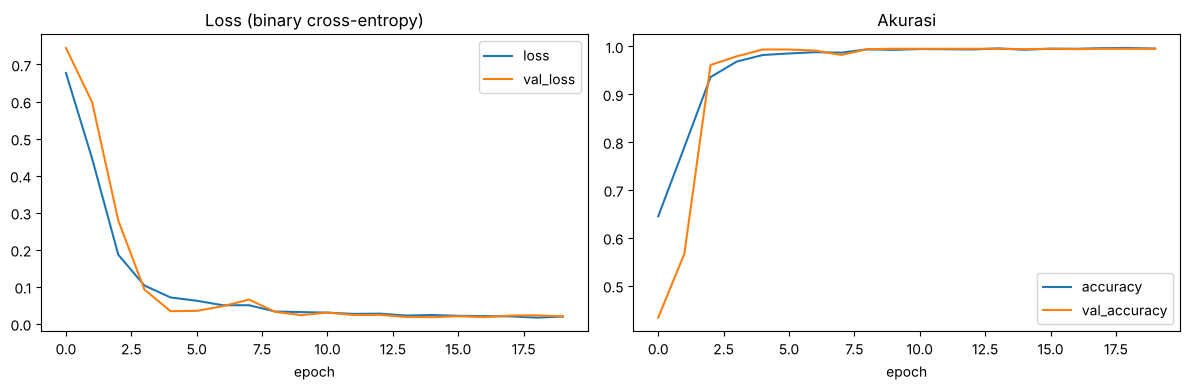

In [ ]:
h = pd.DataFrame(hist.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss (binary cross-entropy)", xlabel="epoch")
h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title="Akurasi", xlabel="epoch")
plt.tight_layout()
plt.savefig(f"{OUT}/kurva_training.png", dpi=120)
plt.show()

## Ambang keputusan (validasi)

In [ ]:
p_val = cnn.predict(X_val, verbose=0).ravel()
t_cnn = pick_threshold(y_val, p_val)

grid = sorted(set(np.round(np.arange(0.05, 0.96, 0.05), 2)) | {0.01, 0.02, 0.03, t_cnn})
cols = ["ambang", "recall_cacat", "fpr", "precision_cacat", "f1"]
print("ambang terpilih:", t_cnn, "| recall val:", round(evaluate(y_val, p_val, t_cnn)["recall_cacat"], 4))
pd.DataFrame([evaluate(y_val, p_val, t) for t in grid])[cols].round(4)

ambang terpilih: 0.07 | recall val: 0.9973


,ambang,recall_cacat,fpr,precision_cacat,f1
0,0.01,0.9987,0.1513,0.8962,0.9447
1,0.02,0.9987,0.0835,0.9399,0.9684
2,0.03,0.9973,0.0609,0.9554,0.9759
3,0.05,0.9973,0.0296,0.9778,0.9875
4,0.07,0.9973,0.0209,0.9843,0.9908
5,0.10,0.9960,0.0157,0.9881,0.9921
6,0.15,0.9934,0.0104,0.9920,0.9927
7,0.20,0.9934,0.0052,0.9960,0.9947
8,0.25,0.9920,0.0035,0.9973,0.9947
9,0.30,0.9907,0.0035,0.9973,0.9940


## Evaluasi di test set

In [ ]:
start = time.time()
p_te = cnn.predict(X_te, verbose=0).ravel()
ms_per_img = (time.time() - start) / len(X_te) * 1000
p_te_all = cnn.predict(X_te_all, verbose=0).ravel()

results["CNN usulan"] = evaluate(y_te, p_te, t_cnn)
print(f"inferensi: {ms_per_img:.1f} ms/citra")
pd.DataFrame({"test bersih (651)": evaluate(y_te, p_te, t_cnn),
              "test asli (715)": evaluate(y_te_all, p_te_all, t_cnn)}).T.round(4)

inferensi: 3.3 ms/citra


,ambang,accuracy,recall_cacat,precision_cacat,f1,fpr,roc_auc,TP,FP,FN,TN,biaya_relatif
test bersih (651),0.07,0.9877,0.9956,0.9869,0.9912,0.0303,0.9997,451.0,6.0,2.0,192.0,26.0
test asli (715),0.07,0.9874,0.9956,0.9847,0.9901,0.0267,0.9998,451.0,7.0,2.0,255.0,27.0


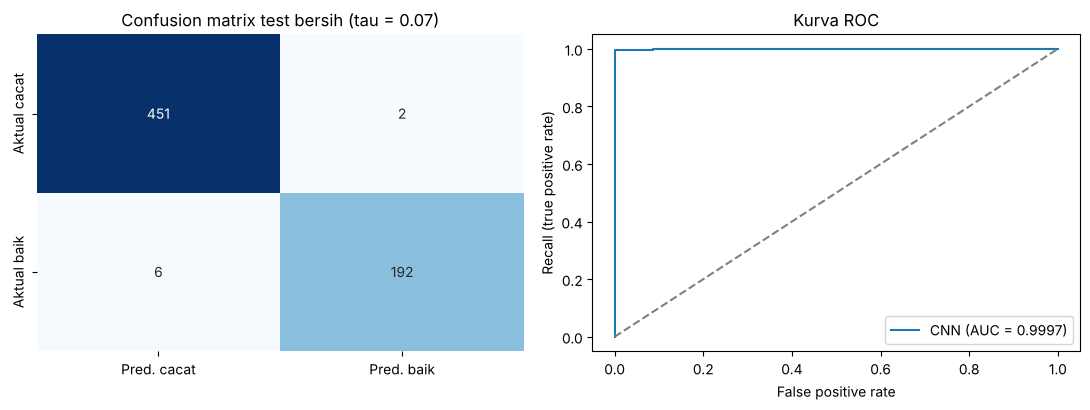

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

cm = confusion_matrix(y_te, (p_te >= t_cnn).astype(int), labels=[1, 0])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Pred. cacat", "Pred. baik"], yticklabels=["Aktual cacat", "Aktual baik"])
ax[0].set_title(f"Confusion matrix test bersih (tau = {t_cnn})")

fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr, label=f"CNN (AUC = {roc_auc_score(y_te, p_te):.4f})")
ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set_xlabel("False positive rate")
ax[1].set_ylabel("Recall (true positive rate)")
ax[1].set_title("Kurva ROC")
ax[1].legend()

plt.tight_layout()
plt.savefig(f"{OUT}/confusion_roc.png", dpi=120)
plt.show()

## Pembanding: MobileNetV2
Base ImageNet dibekukan, input grayscale diduplikasi jadi 3 kanal.

In [ ]:
base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inp = keras.Input((IMG_SIZE, IMG_SIZE, 1))
x = layers.Concatenate()([inp, inp, inp])
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = layers.RandomFlip("horizontal_and_vertical")(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
out = layers.Dense(1, activation="sigmoid")(x)

mnv2 = keras.Model(inp, out, name="mobilenetv2_casting")
mnv2.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
mnv2.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=10, batch_size=32, verbose=2,
         callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])

t_mnv2 = pick_threshold(y_val, mnv2.predict(X_val, verbose=0).ravel())
results["B2 MobileNetV2"] = evaluate(y_te, mnv2.predict(X_te, verbose=0).ravel(), t_mnv2)

Epoch 1/10


166/166 - 42s - 253ms/step - accuracy: 0.8372 - loss: 0.3833 - val_accuracy: 0.9382 - val_loss: 0.2247


Epoch 2/10


166/166 - 40s - 238ms/step - accuracy: 0.9357 - loss: 0.2060 - val_accuracy: 0.9578 - val_loss: 0.1590


Epoch 3/10


166/166 - 44s - 264ms/step - accuracy: 0.9501 - loss: 0.1612 - val_accuracy: 0.9676 - val_loss: 0.1248


... (10 outputs left out)

Epoch 9/10


166/166 - 38s - 227ms/step - accuracy: 0.9819 - loss: 0.0762 - val_accuracy: 0.9827 - val_loss: 0.0669


Epoch 10/10


166/166 - 38s - 231ms/step - accuracy: 0.9812 - loss: 0.0710 - val_accuracy: 0.9894 - val_loss: 0.0578


## Perbandingan model (test bersih)

In [ ]:
n_params = {"B0 Mayoritas": 0,
            "B1 HOG + LogReg": H_tr.shape[1] + 1,
            "B2 MobileNetV2": mnv2.count_params(),
            "CNN usulan": cnn.count_params()}

compare = pd.DataFrame(results).T.loc[list(n_params)]
compare.insert(0, "parameter", pd.Series(n_params))
compare[["parameter", "ambang", "recall_cacat", "fpr", "precision_cacat", "f1",
         "roc_auc", "accuracy", "FN", "FP", "biaya_relatif"]].round(4)

,parameter,ambang,recall_cacat,fpr,precision_cacat,f1,roc_auc,accuracy,FN,FP,biaya_relatif
B0 Mayoritas,0,0.50,1.0000,1.0000,0.6959,0.8207,0.5000,0.6959,0.0,198.0,198.0
B1 HOG + LogReg,1765,0.08,0.9845,0.1970,0.9196,0.9510,0.9895,0.9293,7.0,39.0,109.0
B2 MobileNetV2,2259265,0.44,0.9890,0.0152,0.9933,0.9912,0.9980,0.9877,5.0,3.0,53.0
CNN usulan,101665,0.07,0.9956,0.0303,0.9869,0.9912,0.9997,0.9877,2.0,6.0,26.0


## Uji ketahanan
Simulasi kondisi kamera yang beda: kecerahan ±20%, blur, rotasi 15°.

In [ ]:
def perturb(X, kind):
    out = []
    for x in X[..., 0]:
        if kind == "lebih gelap 20%":
            x = np.clip(x * 0.8, 0, 255)
        elif kind == "lebih terang 20%":
            x = np.clip(x * 1.2, 0, 255)
        elif kind == "blur gaussian 5x5":
            x = cv2.GaussianBlur(x, (5, 5), 0)
        elif kind == "rotasi 15 derajat":
            M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), 15, 1.0)
            x = cv2.warpAffine(x, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REPLICATE)
        out.append(x)
    return np.stack(out)[..., None].astype("uint8")

robust = {}
for kind in ["tanpa gangguan", "lebih gelap 20%", "lebih terang 20%", "blur gaussian 5x5", "rotasi 15 derajat"]:
    r = evaluate(y_te, cnn.predict(perturb(X_te, kind), verbose=0).ravel(), t_cnn)
    robust[kind] = {k: r[k] for k in ["recall_cacat", "fpr", "f1", "FN", "FP"]}
pd.DataFrame(robust).T.round(4)

,recall_cacat,fpr,f1,FN,FP
tanpa gangguan,0.9956,0.0303,0.9912,2.0,6.0
lebih gelap 20%,0.9956,0.0152,0.9945,2.0,3.0
lebih terang 20%,0.9956,0.0051,0.9967,2.0,1.0
blur gaussian 5x5,0.9978,0.0202,0.9945,1.0,4.0
rotasi 15 derajat,0.9978,0.0303,0.9923,1.0,6.0


## Grad-CAM

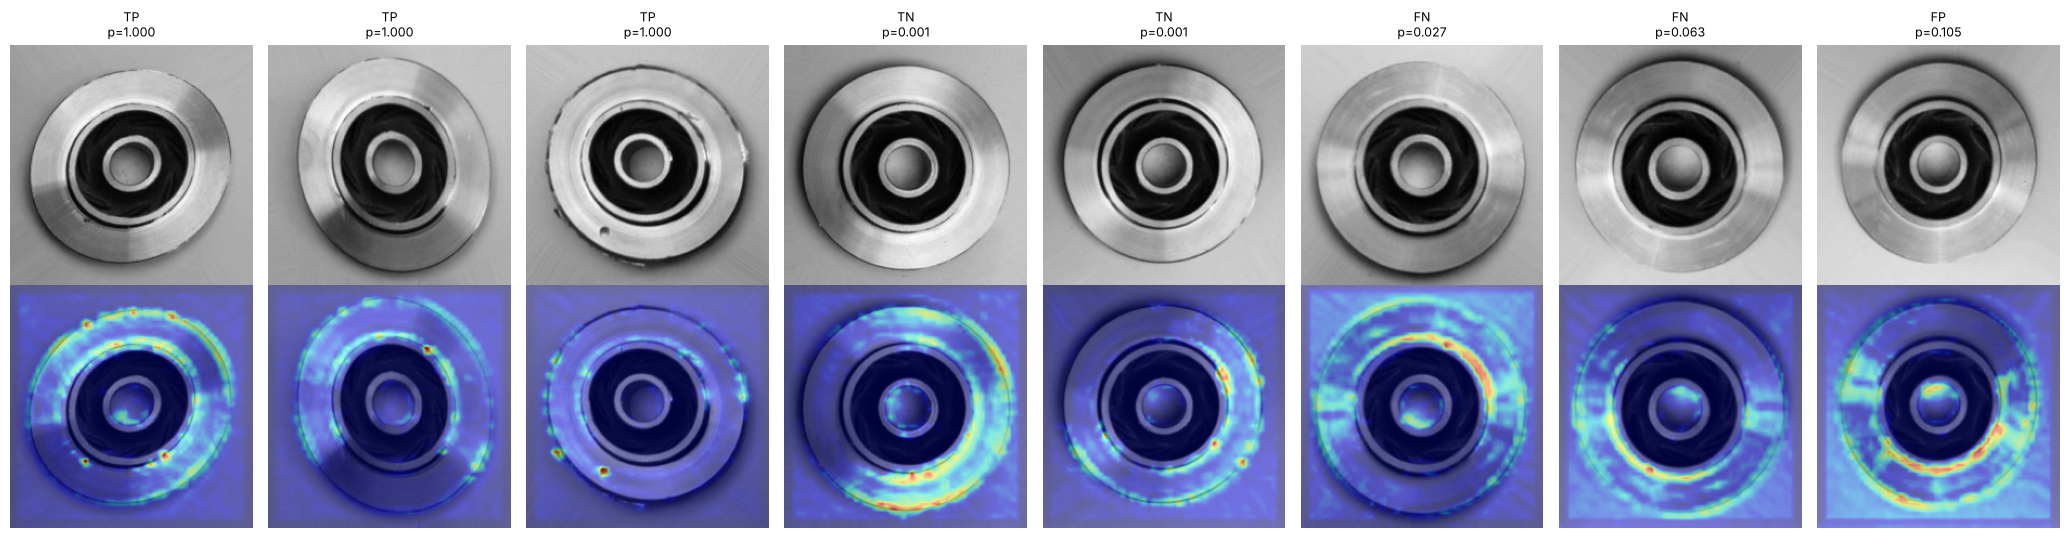

In [ ]:
def gradcam(model, img, layer="relu3"):
    dense_out = model.get_layer("output")
    grad_model = keras.Model(model.inputs, [model.get_layer(layer).output, model.get_layer("dropout").output])
    with tf.GradientTape() as tape:
        conv, feat = grad_model(tf.convert_to_tensor(img[None].astype("float32")), training=False)
        logit = tf.matmul(feat, dense_out.kernel)[:, 0] + dense_out.bias[0]
    grads = tape.gradient(logit, conv)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * weights, axis=-1)).numpy()
    cam /= cam.max() + 1e-8
    return cv2.resize(cam, (IMG_SIZE, IMG_SIZE))

pred = (p_te >= t_cnn).astype(int)
samples = ([("TP", i) for i in np.where((y_te == 1) & (pred == 1))[0][:3]] +
           [("TN", i) for i in np.where((y_te == 0) & (pred == 0))[0][:2]] +
           [("FP" if pred[i] else "FN", i) for i in np.where(y_te != pred)[0][:3]])

fig, axes = plt.subplots(2, len(samples), figsize=(2.6 * len(samples), 5.4))
for c, (tag, i) in enumerate(samples):
    axes[0, c].imshow(X_te[i, ..., 0], cmap="gray")
    axes[0, c].set_title(f"{tag}\np={p_te[i]:.3f}", fontsize=9)
    axes[1, c].imshow(X_te[i, ..., 0], cmap="gray")
    axes[1, c].imshow(gradcam(cnn, X_te[i]), cmap="jet", alpha=0.45)
    axes[0, c].axis("off")
    axes[1, c].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/gradcam.png", dpi=120)
plt.show()

## Simpan model & metrik


In [ ]:
cnn.save(f"{OUT}/model_casting.keras")

def to_py(d):
    return {k: v.item() if hasattr(v, "item") else v for k, v in d.items()}

metrics = {
    "ambang": t_cnn,
    "target_recall": 0.99,
    "aturan_ambang": "biaya minimum 10*FN + FP di validasi",
    "img_size": IMG_SIZE,
    "ms_per_citra": round(ms_per_img, 2),
    "epoch_dijalankan": len(hist.history["loss"]),
    "waktu_latih_menit": round(train_time / 60, 1),
    "duplikat_dihapus": int(df.dup.sum()),
    "split": {k: to_py(v) for k, v in split_info.T.to_dict().items()},
    "test_bersih": to_py(results["CNN usulan"]),
    "test_asli": to_py(evaluate(y_te_all, p_te_all, t_cnn)),
    "perbandingan": {k: {**to_py(v), "parameter": int(n_params[k])} for k, v in results.items()},
    "ketahanan": {k: to_py(v) for k, v in robust.items()},
}
with open(f"{OUT}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

os.makedirs(f"{OUT}/contoh_uji", exist_ok=True)
for cls in LABELS:
    for p in test_df[test_df.kelas == cls].sample(4, random_state=SEED).path:
        Image.open(p).convert("L").save(f"{OUT}/contoh_uji/{os.path.basename(p)}")

metrics["test_bersih"]

{'ambang': 0.07,
 'accuracy': 0.9877112135176651,
 'recall_cacat': 0.9955849889624724,
 'precision_cacat': 0.986870897155361,
 'f1': 0.9912087912087912,
 'fpr': 0.030303030303030304,
 'roc_auc': 0.9997435725912547,
 'TP': 451,
 'FP': 6,
 'FN': 2,
 'TN': 192,
 'biaya_relatif': 26}

In [ ]:
import shutil
shutil.make_archive("outputs", "zip", OUT)

from google.colab import files
files.download("outputs.zip")